In [16]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import normalize, StandardScaler
from utils.ACC_train_bestVoter_ensemble import *
import joblib

In [11]:
root_path = f'/home/jovyan/private/slums/data/PARTIMAP'

city = "ACC"
base_name = "communities"
d_src = "S1_200m"
tbl_name = f'{city}_{base_name}_votes'
se=1
euclid=0
n_epochs = 1000
n_width = 20
n_height = 20
n_channels = 2
n_batch = 64
BATCH_SIZE = 64

db_path = f'{root_path}/votes/db/{city}/{city}_voterAI.db'
tbl_name = f'{city}_{base_name}_pairs'
base_model = f"{city}_voter_{base_name}"
model_name = f"{base_model}_ensembleVoter"
model_dir = "/home/jovyan/private/slums/data/PARTIMAP/trained_models/voter/"+model_name+"_"+d_src+"_1_bradley_terry.ckpt"

In [3]:
def retrieve_db(db_path, sql):
    con = sqlite3.connect(db_path)
    return con, pd.read_sql(sql, con = con)
def import_votes(db_path, tbl_name, n_votes=-1):
    sql = f"select * from " + tbl_name
    con, all_data = retrieve_db(db_path, sql)
    if n_votes != -1:
        all_data = all_data.sample(n=n_votes)
    return all_data
def load_and_preprocess_image(fp, sub_bands, norm_data=False):
    # Load image using GDAL
    # print(fp,end='\r')
    img_dataset = gdal.Open(fp)
    img_array = img_dataset.ReadAsArray()
    if norm_data:
        img_array = (img_array - np.min(img_array)) / (np.max(img_array) - np.min(img_array))
    if sub_bands is not None:
        img_array = img_array[sub_bands,:,:]
    return np.transpose(img_array[:, :20, :20], (1, 2, 0))

In [8]:
# 1. Load the model and extract the encoder
full_model = tf.keras.models.load_model(model_dir)
nested_model = full_model.layers[2]
single_encoder = nested_model.get_layer('feature_extractor')

Model: "model_1_1_1_1_2_1_3_1_4_1_5"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 left_image (InputLayer)        [(None, 20, 20, 2)]  0           []                               
                                                                                                  
 right_image (InputLayer)       [(None, 20, 20, 2)]  0           []                               
                                                                                                  
 feature_extractor (Functional)  (None, 2, 2, 64)    112178      ['left_image[0][0]',             
                                                                  'right_image[0][0]']            
                                                                                                  
 flatten (Flatten)              (None, 256)          0           ['featu

In [9]:
sub_bands, n_width, n_height, n_channels = get_sub_bands(d_src)
# data_frac = np.arange(0.1,1.1,0.1)
data_frac = [1]
norm_data = 0
# Data loading
all_data = import_votes(db_path, tbl_name)

# if "planners" in base_name:
#     pl_data = import_votes(db_path, pl_tbl_name)
#     all_data = pl_data.copy()
# elif "communities" in base_name:
#     cm_data = import_votes(db_path, cm_tbl_name)
#     all_data = cm_data.copy()
# elif "combined" in base_name:
#     cb_data = import_votes(db_path, cb_tbl_name)
#     all_data = cb_data.copy()

In [10]:
print(len(all_data))

11784


In [12]:
print("\n" + "="*60)
print("EXTRACTING PAIRWISE EMBEDDINGS")
print("="*60)
 
train_pair_concat = []  # Concatenated: [features_L, features_R] (512D)
train_pair_diff = []    # Difference: features_L - features_R (256D)
 
print(f"Processing {len(all_data)} pairs in batches of {BATCH_SIZE}...")
 
for i in range(0, len(all_data), BATCH_SIZE):
    if i % (BATCH_SIZE * 10) == 0:
        print(f"  Processed {i}/{len(all_data)} pairs", end='\r')
    
    batch_df = all_data.iloc[i: i + BATCH_SIZE]
    
    # Load images
    batch_l = [load_and_preprocess_image(root_path + "/" + row.left, sub_bands) 
               for row in batch_df.itertuples()]
    batch_r = [load_and_preprocess_image(root_path + "/" + row.right, sub_bands) 
               for row in batch_df.itertuples()]
    
    # Extract features using single encoder
    features_l = single_encoder(np.array(batch_l)).numpy()  # (batch, 2, 2, 64)
    features_r = single_encoder(np.array(batch_r)).numpy()  # (batch, 2, 2, 64)
    
    # Flatten spatial dimensions
    features_l_flat = features_l.reshape(features_l.shape[0], -1)  # (batch, 256)
    features_r_flat = features_r.reshape(features_r.shape[0], -1)  # (batch, 256)
    
    # Create pairwise representations
    # 1. Concatenation (similar to previous joint representation)
    pair_concat = np.concatenate([features_l_flat, features_r_flat], axis=1)  # (batch, 512)
    train_pair_concat.extend(pair_concat)
    
    # 2. Difference (BT-aligned representation)
    pair_diff = features_l_flat - features_r_flat  # (batch, 256)
    train_pair_diff.extend(pair_diff)
 
train_pair_concat = np.array(train_pair_concat)  # (N_pairs, 512)
train_pair_diff = np.array(train_pair_diff)      # (N_pairs, 256)
 
print(f"\n✓ Extracted {len(train_pair_concat)} pairwise embeddings")
print(f"  - Concatenated shape: {train_pair_concat.shape}")
print(f"  - Difference shape: {train_pair_diff.shape}")


EXTRACTING PAIRWISE EMBEDDINGS
Processing 11784 pairs in batches of 64...


2026-05-23 00:02:23.309809: W tensorflow/stream_executor/gpu/asm_compiler.cc:230] Falling back to the CUDA driver for PTX compilation; ptxas does not support CC 8.9
2026-05-23 00:02:23.309834: W tensorflow/stream_executor/gpu/asm_compiler.cc:233] Used ptxas at ptxas
2026-05-23 00:02:23.310003: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] UNIMPLEMENTED: ptxas ptxas too old. Falling back to the driver to compile.
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


  Processed 11520/11784 pairs
✓ Extracted 11784 pairwise embeddings
  - Concatenated shape: (11784, 512)
  - Difference shape: (11784, 256)


In [13]:
# ============================================================================
# Extract Single-Image Embeddings
# ============================================================================
 
print("\n" + "="*60)
print("EXTRACTING SINGLE-IMAGE EMBEDDINGS")
print("="*60)
 
unique_images = pd.concat([all_data['left'], all_data['right']]).unique()
print(f"Processing {len(unique_images)} unique images...")
 
train_single_embeddings = []
 
for i in range(0, len(unique_images), BATCH_SIZE):
    if i % (BATCH_SIZE * 10) == 0:
        print(f"  Processed {i}/{len(unique_images)} images", end='\r')
    
    batch_paths = unique_images[i: i + BATCH_SIZE]
    
    # Load images
    batch_imgs = [load_and_preprocess_image(root_path + "/" + path, sub_bands) 
                  for path in batch_paths]
    
    # Extract features
    features = single_encoder(np.array(batch_imgs)).numpy()  # (batch, 2, 2, 64)
    
    # Flatten
    features_flat = features.reshape(features.shape[0], -1)  # (batch, 256)
    train_single_embeddings.extend(features_flat)
 
train_single_embeddings = np.array(train_single_embeddings)  # (N_images, 256)
 
print(f"\n✓ Extracted {len(train_single_embeddings)} single-image embeddings")
print(f"  - Shape: {train_single_embeddings.shape}")


EXTRACTING SINGLE-IMAGE EMBEDDINGS
Processing 660 unique images...
  Processed 640/660 images
✓ Extracted 660 single-image embeddings
  - Shape: (660, 256)


In [17]:
# ============================================================================
# PCA Configuration
# ============================================================================
 
# How many components to keep for each embedding type?
PCA_COMPONENTS = {
    'single': 64,        # 256D → 64D  (75% reduction)
    'pair_concat': 128,  # 512D → 128D (75% reduction)
    'pair_diff': 64      # 256D → 64D  (75% reduction)
}
 
# Alternative: Keep components that explain X% of variance
USE_VARIANCE_THRESHOLD = False
VARIANCE_THRESHOLD = 0.95  # Keep 95% of variance

In [18]:
print(f"Original embedding shapes:")
print(f"  Single:     {train_single_embeddings.shape}")
print(f"  Concat:     {train_pair_concat.shape}")
print(f"  Difference: {train_pair_diff.shape}")

# ============================================================================
# Apply PCA to Each Embedding Type
# ============================================================================
 
print("\n" + "="*60)
print("APPLYING PCA DIMENSIONALITY REDUCTION")
print("="*60)
 
# --- 1. Single-Image Embeddings ---
print("\n1. Single-image embeddings (256D → 64D)")
 
scaler_single = StandardScaler()
train_single_scaled = scaler_single.fit_transform(train_single_embeddings)
 
if USE_VARIANCE_THRESHOLD:
    pca_single = PCA(n_components=VARIANCE_THRESHOLD, svd_solver='full')
else:
    pca_single = PCA(n_components=PCA_COMPONENTS['single'])
 
train_single_pca = pca_single.fit_transform(train_single_scaled)
 
variance_explained = np.sum(pca_single.explained_variance_ratio_)
print(f"✓ Reduced to {train_single_pca.shape[1]}D")
print(f"  Variance explained: {variance_explained:.1%}")
 
# --- 2. Concatenated-Pair Embeddings ---
print("\n2. Concatenated-pair embeddings (512D → 128D)")
 
scaler_concat = StandardScaler()
train_concat_scaled = scaler_concat.fit_transform(train_pair_concat)
 
if USE_VARIANCE_THRESHOLD:
    pca_concat = PCA(n_components=VARIANCE_THRESHOLD, svd_solver='full')
else:
    pca_concat = PCA(n_components=PCA_COMPONENTS['pair_concat'])
 
train_concat_pca = pca_concat.fit_transform(train_concat_scaled)
 
variance_explained = np.sum(pca_concat.explained_variance_ratio_)
print(f"✓ Reduced to {train_concat_pca.shape[1]}D")
print(f"  Variance explained: {variance_explained:.1%}")
 
# --- 3. Difference Embeddings (BT-specific) ---
print("\n3. Difference embeddings (256D → 64D)")
 
scaler_diff = StandardScaler()
train_diff_scaled = scaler_diff.fit_transform(train_pair_diff)
 
if USE_VARIANCE_THRESHOLD:
    pca_diff = PCA(n_components=VARIANCE_THRESHOLD, svd_solver='full')
else:
    pca_diff = PCA(n_components=PCA_COMPONENTS['pair_diff'])
 
train_diff_pca = pca_diff.fit_transform(train_diff_scaled)
 
variance_explained = np.sum(pca_diff.explained_variance_ratio_)
print(f"✓ Reduced to {train_diff_pca.shape[1]}D")
print(f"  Variance explained: {variance_explained:.1%}")

Original embedding shapes:
  Single:     (660, 256)
  Concat:     (11784, 512)
  Difference: (11784, 256)

APPLYING PCA DIMENSIONALITY REDUCTION

1. Single-image embeddings (256D → 64D)
✓ Reduced to 64D
  Variance explained: 86.9%

2. Concatenated-pair embeddings (512D → 128D)
✓ Reduced to 128D
  Variance explained: 88.5%

3. Difference embeddings (256D → 64D)
✓ Reduced to 64D
  Variance explained: 87.5%


In [19]:
# ============================================================================
# Train Isolation Forests on PCA-Reduced Embeddings
# ============================================================================
 
print("\n" + "="*60)
print("TRAINING ISOLATION FORESTS")
print("="*60)
 
output_dir = f'/home/jovyan/private/where_transfer/models'
 
# --- 1. Single-Image Isolation Forest ---
print("\n1. Training single-image Isolation Forest...")
iso_single = IsolationForest(
    n_estimators=200, 
    contamination='auto', 
    random_state=42,
    n_jobs=-1
)
iso_single.fit(train_single_pca)  # Using PCA-reduced embeddings
 
# Save both the PCA and Isolation Forest
joblib.dump(scaler_single, f'{output_dir}/{city}_{base_name}_single_scaler.joblib')
joblib.dump(pca_single, f'{output_dir}/{city}_{base_name}_single_pca.joblib')
joblib.dump(iso_single, f'{output_dir}/{city}_{base_name}_single_iso_pca.joblib')
 
print(f"✓ Saved single-image models")
print(f"  Input:  256D → StandardScaler → PCA → {train_single_pca.shape[1]}D → IsolationForest")
 
# --- 2. Concatenated-Pair Isolation Forest ---
print("\n2. Training concatenated-pair Isolation Forest...")
iso_pair_concat = IsolationForest(
    n_estimators=200, 
    contamination='auto', 
    random_state=42,
    n_jobs=-1
)
iso_pair_concat.fit(train_concat_pca)
 
joblib.dump(scaler_concat, f'{output_dir}/{city}_{base_name}_pair_concat_scaler.joblib')
joblib.dump(pca_concat, f'{output_dir}/{city}_{base_name}_pair_concat_pca.joblib')
joblib.dump(iso_pair_concat, f'{output_dir}/{city}_{base_name}_pair_concat_iso_pca.joblib')
 
print(f"✓ Saved concatenated-pair models")
print(f"  Input:  512D → StandardScaler → PCA → {train_concat_pca.shape[1]}D → IsolationForest")
 
# --- 3. Difference Isolation Forest ---
print("\n3. Training difference Isolation Forest (BT-specific)...")
iso_pair_diff = IsolationForest(
    n_estimators=200, 
    contamination='auto', 
    random_state=42,
    n_jobs=-1
)
iso_pair_diff.fit(train_diff_pca)
 
joblib.dump(scaler_diff, f'{output_dir}/{city}_{base_name}_pair_diff_scaler.joblib')
joblib.dump(pca_diff, f'{output_dir}/{city}_{base_name}_pair_diff_pca.joblib')
joblib.dump(iso_pair_diff, f'{output_dir}/{city}_{base_name}_pair_diff_iso_pca.joblib')
 
print(f"✓ Saved difference models")
print(f"  Input:  256D → StandardScaler → PCA → {train_diff_pca.shape[1]}D → IsolationForest")


TRAINING ISOLATION FORESTS

1. Training single-image Isolation Forest...
✓ Saved single-image models
  Input:  256D → StandardScaler → PCA → 64D → IsolationForest

2. Training concatenated-pair Isolation Forest...
✓ Saved concatenated-pair models
  Input:  512D → StandardScaler → PCA → 128D → IsolationForest

3. Training difference Isolation Forest (BT-specific)...
✓ Saved difference models
  Input:  256D → StandardScaler → PCA → 64D → IsolationForest



PCA VARIANCE ANALYSIS

✓ Saved variance plot: ACC_communities_pca_variance.png


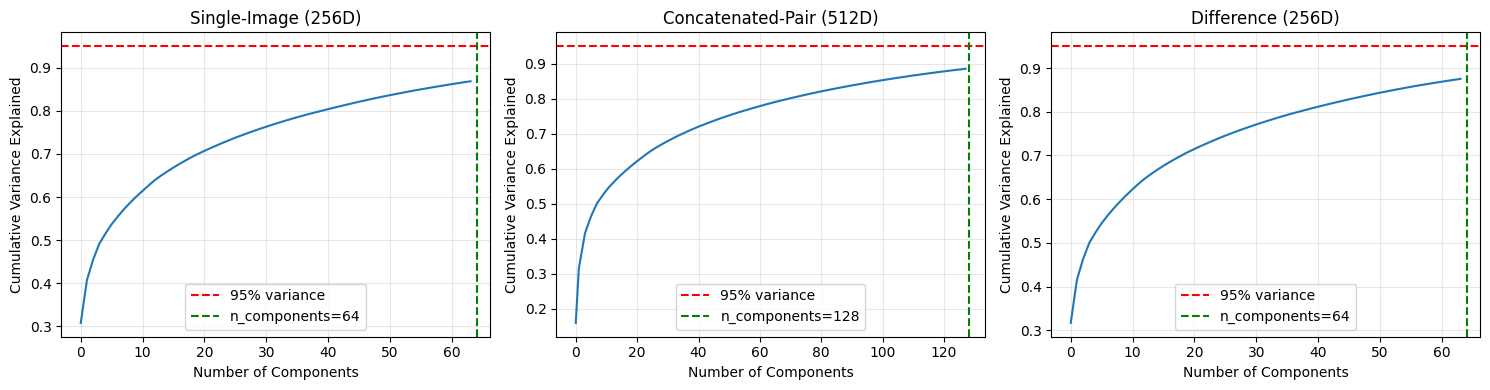

In [20]:
# ============================================================================
# Visualize PCA Variance Explained
# ============================================================================
 
print("\n" + "="*60)
print("PCA VARIANCE ANALYSIS")
print("="*60)
 
import matplotlib.pyplot as plt
 
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
 
# Plot cumulative variance explained for each PCA
for idx, (pca, name) in enumerate([
    (pca_single, 'Single-Image (256D)'),
    (pca_concat, 'Concatenated-Pair (512D)'),
    (pca_diff, 'Difference (256D)')
]):
    cumsum = np.cumsum(pca.explained_variance_ratio_)
    axes[idx].plot(cumsum)
    axes[idx].axhline(y=0.95, color='r', linestyle='--', label='95% variance')
    axes[idx].axvline(x=pca.n_components_, color='g', linestyle='--', 
                      label=f'n_components={pca.n_components_}')
    axes[idx].set_xlabel('Number of Components')
    axes[idx].set_ylabel('Cumulative Variance Explained')
    axes[idx].set_title(name)
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)
 
plt.tight_layout()
plt.savefig(f'{output_dir}/{city}_{base_name}_pca_variance.png', dpi=150)
print(f"\n✓ Saved variance plot: {city}_{base_name}_pca_variance.png")

In [21]:
# ============================================================================
# Summary
# ============================================================================
 
print("\n" + "="*60)
print("TRAINING COMPLETE WITH PCA")
print("="*60)
 
summary_data = [
    ['Single-Image', f'256D → {train_single_pca.shape[1]}D', 
     f"{np.sum(pca_single.explained_variance_ratio_):.1%}",
     len(train_single_pca)],
    ['Concat-Pair', f'512D → {train_concat_pca.shape[1]}D', 
     f"{np.sum(pca_concat.explained_variance_ratio_):.1%}",
     len(train_concat_pca)],
    ['Difference', f'256D → {train_diff_pca.shape[1]}D', 
     f"{np.sum(pca_diff.explained_variance_ratio_):.1%}",
     len(train_diff_pca)]
]
 
print("\nPipeline for each embedding type:")
print("  Raw Features → StandardScaler → PCA → IsolationForest")
print("\nDimensionality Reduction:")
for name, dims, var, n_samples in summary_data:
    print(f"  {name:15} {dims:20} {var:>7} variance | {n_samples:,} samples")
 
print("\nSaved models for each type (9 files total):")
print("  - StandardScaler (.joblib)")
print("  - PCA (.joblib)")
print("  - IsolationForest (.joblib)")
print("="*60)


TRAINING COMPLETE WITH PCA

Pipeline for each embedding type:
  Raw Features → StandardScaler → PCA → IsolationForest

Dimensionality Reduction:
  Single-Image    256D → 64D             86.9% variance | 660 samples
  Concat-Pair     512D → 128D            88.5% variance | 11,784 samples
  Difference      256D → 64D             87.5% variance | 11,784 samples

Saved models for each type (9 files total):
  - StandardScaler (.joblib)
  - PCA (.joblib)
  - IsolationForest (.joblib)
